In [1]:
import os
import sys
import matplotlib.pyplot as plt
import torch
import numpy as np
from matplotlib.colors import LogNorm
from torch.distributed.tensor import zeros
import json
# Add the parent directory of 'model' to sys.path
sys.path.append("D:\\pythonproject\\envTest\\")
from MDN import mdn, Mixture
from cVAE import cVAE
from cVAE_ori import cVAE as cVAE_prev
from tortreinador.models.MDN import mdn as mdn_ori
from tortreinador.utils.View import init_weights
import joblib
import matplotlib.ticker as ticker
from sklearn.exceptions import InconsistentVersionWarning
import matplotlib.gridspec as gridspec
import warnings
import math
from typing import Sequence
from tqdm import tqdm
from matplotlib.colors import LogNorm

import pandas as pd
from matplotlib.ticker import ScalarFormatter, MaxNLocator
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=InconsistentVersionWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Used for ppt charts
plt.rcParams['axes.labelcolor'] = 'black'     # xlabel、ylabel
plt.rcParams['xtick.color']     = 'black'    # x 轴刻度文字
plt.rcParams['ytick.color']     = 'black'  # y 轴刻度文字
plt.rcParams['legend.edgecolor'] = 'white'  # 图例边框颜色
plt.rcParams['legend.facecolor'] = 'white'  # 图例背景色
plt.rcParams['text.color']      = 'black'    # 其他文本
plt.rcParams['axes.grid'] = False
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'

plt.rcParams["text.usetex"] = False
# plt.rcParams["text.latex.preamble"] = r"\usepackage{newtxtext,newtxmath}"
# plt.rcParams["ps.fonttype"]  = 42

In [2]:
def chart_preference(ax,
                     sub_dict_length: int = 0,
                     label_name: str = None,
                     label_font_size: int = 16,
                     tick_labelsize: int = 14,
                     xlocator: float = None,
                     xminorlocator: float = None,
                     ylocator: float = None,
                     yminorlocator: float = None,
                     inset_space: Sequence[float] = None,
                     style: str = 'full',
                     y_label: str = 'Normalized Signed Error',
                     all_subplots_ylabel: bool = False,
                     display_zero_lines: bool = True,
                     legend_display: bool = True,
                     y_ticks_display: bool = True):
    if style not in ['full', 'plain']:
        raise ValueError("Expect 'full' or 'plain' style, but found style as {}".format(style))

    if display_zero_lines:
        ax.axhline(y=0, color='red', linestyle='--', zorder=sub_dict_length)
    
    ax.tick_params(axis='x', which='both', bottom=True, top=False, direction='out', labelsize=tick_labelsize)
    
    
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color('black')
    
    if style == 'full':
        if xlocator:
            ax.xaxis.set_major_locator(ticker.MultipleLocator(xlocator))
    
        if xminorlocator:
            ax.xaxis.set_minor_locator(ticker.MultipleLocator(xminorlocator))
        
        ax.set_xlabel(label_name, fontsize=label_font_size)

        if all_subplots_ylabel:
            ax.set_ylabel(y_label, fontsize=label_font_size)

        else:
            if o == 0 or o == 4:
                ax.set_ylabel(y_label, fontsize=label_font_size)

        if o == 0 and legend_display:
            ax.legend(
                # title=title,
                frameon=True,
                framealpha=0.7,
                loc='lower right',
                fontsize=9,
                facecolor='whitesmoke',
                edgecolor='gray',
            )
        # if o == 5 or 0 == 6 or o == 7:
                
        ax.tick_params(axis='y', which='both', left=True, right=False, direction='out', labelsize=tick_labelsize, pad=2)
        
    else:
        ax.tick_params(axis='y', which='both', left=True, right=False, direction='out', labelsize=tick_labelsize, pad=0.5)
    
    if ylocator:
        ax.yaxis.set_major_locator(ticker.MultipleLocator(ylocator))
    
    if yminorlocator:
        ax.yaxis.set_minor_locator(ticker.MultipleLocator(yminorlocator))
    
    if inset_space is not None:
        # if style == 'plain':
        print("Processing inset space")
        ax.yaxis.set_major_locator(ticker.FixedLocator(inset_space))

    if not y_ticks_display:
        ax.set_yticks([])
    
    # return ax

def dis_limitation(minimum_dis, maximum_dis):
    
    if minimum_dis < -200:
        tmp_minimum_dis = -200
    
    else:
        tmp_minimum_dis = minimum_dis
    
    if maximum_dis > 200:
        tmp_maximum_dis = 200
    
    else:
        tmp_maximum_dis = maximum_dis
    
    return tmp_minimum_dis, tmp_maximum_dis

def plot_amplitude(tmp_ax, key_length, color_list, slide_collection, window, c, label_text, rasterized: bool = True):
    if key_length == 2:
        color_tmp = [color_list[0], color_list[-3]]
        tmp_ax.fill_between(slide_collection, window[:, 0], window[:, 1],
                            facecolor=(switch_rgb(color_tmp[c])),
                            zorder=key_length - c, edgecolor=switch_rgb(color_tmp[c]), label=label_text,
                            rasterized=rasterized)

    else:
        tmp_ax.fill_between(slide_collection, window[:, 0], window[:, 1],
                            facecolor=(switch_rgb(color_list[c])),
                            zorder=key_length - c, edgecolor=switch_rgb(color_list[c]), label=label_text,
                            rasterized=rasterized)
    
    # return tmp_ax
def scientific_notation(v, fixed_exp=None):
    if v == 0:
        return 0.0
    if math.isnan(v):
        return float('nan'), 0
    if math.isinf(v):
        return float('inf') if v > 0 else float('-inf'), 0
    
    sign = -1 if v < 0 else 1
    x = abs(v)
    e = math.floor(math.log10(x)) if fixed_exp is None else fixed_exp
    m = x / (10 ** e)
    m = sign * m
    # print(f"{x} -> {round(m, 3)} x 10^{e}")        

    # return '${} x 10^{}$'.format(m, e)
    return '{}'.format(m)

def get_columns_r2(y_ture, y_pred):
    ss_tot = torch.sum(((torch.from_numpy(y_ture) - torch.mean(torch.from_numpy(y_ture), dim=0)) ** 2), dim=0,
                       dtype=torch.float64)
    ss_res = torch.sum(((torch.from_numpy(y_ture) - torch.from_numpy(y_pred)) ** 2), dim=0, dtype=torch.float64)
    r2s = 1 - ss_res / ss_tot
    r2s = r2s.detach().numpy()
    return r2s

def switch_rgb(hex_color, alpha=None):
    if hex_color.startswith('#'):
        hex_color = hex_color[1:]

    if alpha is not None:
        return tuple(int(hex_color[i: i+2], 16) / 256 for i in (0, 2, 4)) + (alpha,)

    else:
        return tuple(int(hex_color[i: i + 2], 16) / 256 for i in (0, 2, 4))

def sampling_from_gmm_pdf(gmm, y_l_):
    bins = np.concatenate(([y_l_[0, 0]], y_l_[:, 0]))
    d_x = {param: [] for param in output_parameters}
    # density_y = {param: [] for param in output_parameters}

    # Loop start here
    for out_param in range(len(output_parameters)):
        GMM_PDF_Tor_sub = gmm[:, :, out_param]

        GMM_PDF_Tor_sub_sum = GMM_PDF_Tor_sub.sum(axis=1)[:, np.newaxis]

        prob = np.divide(GMM_PDF_Tor_sub, GMM_PDF_Tor_sub_sum)
        non_zero = np.count_nonzero(GMM_PDF_Tor_sub, axis=1)

        cond = np.where(GMM_PDF_Tor_sub_sum == 0, True, False)
        p = np.where(cond, 1 / len(y_l_), prob)
        size_cond = np.where((non_zero < 20) & (non_zero > 0), non_zero, np.where(non_zero == 0, 20, 20))

        idx = [np.random.choice(y_l_[:, 0], size=size_cond[i], replace=cond[i, 0], p=p[i, :]) for i in range(len(GMM_PDF_Tor_sub))]
        indices = [np.searchsorted(bins, idx[i]) - 1 for i in range(len(idx))]
        flattened_indices = np.concatenate(indices)
        d_x[output_parameters[out_param]] = np.concatenate([d_x[output_parameters[out_param]], y_l_[:, 0][flattened_indices].ravel()])

    return d_x

def calculate_GMM(p, m, s, y_label):
    """
    Calculate the probability density function of the Gaussian Mixture Model

        Args:
            - param p: pi
            - param m: mean
            - param s: standard deviation
            - param y_label: e.g. np.arange(0, 1, 0.001)

    """
    if len(y_label.shape) == 1:
        y_label = y_label.reshape(-1, 1)

    y_label_ = y_label[:, np.newaxis, np.newaxis, :]

    mu_sub_T = np.transpose(m, (0, 2, 1))
    sigma_sub_T = np.transpose(s, (0, 2, 1))

    exponent = np.exp(
        -1 / 2 * np.square(np.transpose((y_label_ - mu_sub_T), (1, 2, 0, 3)) / sigma_sub_T[:, :, np.newaxis, :]))
    factors = 1 / math.sqrt(2 * math.pi) / sigma_sub_T[:, :, np.newaxis, :]

    # Shape (number of data, number of y_label, types) e.g.(1000, 10, 8)
    GMM_PDF = np.sum(p[:, np.newaxis, np.newaxis, :] * factors * exponent, axis=-1).transpose((0, -1, 1))
    # GMM_PDF = GMM_PDF.reshape(GMM_PDF.shape[0] * GMM_PDF.shape[1], GMM_PDF.shape[-1]).transpose((-1, 0))
    # f = e.transpose((-1, 0))
    return GMM_PDF

In [3]:
input_parameters = [
    'Mass',
    'Radius',
    'FeMg',
    'SiMg',
]

output_parameters = [
    'WRF',
    'MRF',
    'CRF',
    'WMF',
    'CMF',
    'CPS',
    'CTP',
    'k2'
]

x_labels = [
    'WRF',
    'MRF',
    'CRF',
    'WMF',
    'CMF',
    '$P_{\mathrm{CMB}}$(TPa)',
    '$T_{\mathrm{CMB}}(10^{3}$K$)$',
    '$k_{2}$'
]
xlocators = [0.05, 0.2, 0.2, 0.02, 0.2, 0.4, 1, 0.2]

# ylocators_set_1 = [100, 20, 70, 100, 100, 30, 6.5, 8]
# ylocators_set_2 = [100, 25, 50, 100, 100, 60, 10, 10]
# ylocators_set_3 = [100, 25, 50, 100, 100, 100, 10, 10]
# 
# yminorlocators_set_1 = [20, 4, 14, 20, 20, 6, 1.3, 1.6]
# yminorlocators_set_2 = [20, 5, 10, 20, 20, 12, 2, 2]
# yminorlocators_set_3 = [20, 5, 10, 20, 20, 20, 2, 2]

ylocators_set_1 = [100, 20, 50, 100, 100, 100, 10, 20]
ylocators_set_2 = [100, 20, 50, 100, 100, 100, 10, 20]
ylocators_set_3 = [100, 20, 50, 100, 100, 100, 10, 20]

yminorlocators_set_1 = [20, 4, 10, 20, 20, 20, 2, 4]
yminorlocators_set_2 = [20, 4, 10, 20, 20, 20, 2, 4]
yminorlocators_set_3 = [20, 4, 10, 20, 20, 20, 2, 4]

xminorlocators = [0.01, 0.04, 0.04, 0.004, 0.04, 0.08, 0.2, 0.04]



# y_max = [200, 75, 150, 200, 200, ]
# y_min = []

img_save_path = ".\\imgs"

colors = ['#2E2252', '#4B3C6A', '#71628E', '#988FB8', '#C5BCDB']
colors_2 = ['#003744', '#005C6D', '#007F8F', '#00A1B2', '#4DD4DE']  # for paper
colors_3 = ['#0D1B2A', '#1B263B', '#415A77', '#778DA9', '#E0E1DD']
colors_for_ppt = ['#91662b', '#a38f66', '#c9ae76']


def title_process(t, mode='scaler'):
    
    if mode == 'scaler':
        return t.split('_')[0] if t.split('_')[0] != '50' else t.split('_')[0] + '_' + t.split('_')[1]
    
    elif mode == 'test_data':
        return t.split('_')[2].split('.')[0] if t.split('_')[2].split('.')[0] != '50' else t.split('_')[-2] + '_' + t.split('_')[-1].split('.')[0]

In [4]:
base_file_path = ".\\data"
cvae_base_file_path = os.path.join(base_file_path, "cVAE")
MDN_base_file_path = os.path.join(base_file_path, "MDN")
TIMES = 20
DEVICE = 'cuda'
y_l = np.arange(0, 1, 0.001).reshape(-1, 1)


In [5]:

sample_size = 75000
# selected_idx = np.random.choice(range(705600), size=sample_size)
selected_idx = np.arange(sample_size)

# model_list = np.array(["5th_best_model.pth", "50th_best_model.pth", "95th_best_model.pth", "ori_best_model.pth"])
model_list = np.array(["5th", "50th", "95th", "ori"])
model_name = "best_model.pth"
cvae_model = cVAE(i_dim=len(output_parameters), z_dim=int(len(output_parameters) * 7), num_hidden=1024,
                  c_dim=len(input_parameters), o_dim=len(output_parameters))
init_weights(cvae_model)
cvae_model.eval()

cvae_prev = cVAE_prev(i_dim=len(output_parameters), z_dim=int(len(output_parameters) * 7), num_hidden=1024,
                  c_dim=len(input_parameters), o_dim=len(output_parameters))
init_weights(cvae_prev)
cvae_prev.eval()

mix = Mixture()
scaler_dicts = {}
model_result_dicts = {}
# processing
for l in model_list:

    cvae_file_path = os.path.join(cvae_base_file_path, l)
    mdn_file_path = os.path.join(MDN_base_file_path, l)

    scaler_dicts['cvae_' + l] = [joblib.load(os.path.join(base_file_path, l, "scaler_x.save")),
                                         joblib.load(os.path.join(base_file_path, l, "scaler_y.save"))]

    scaler_dicts['mdn_' + l] = [joblib.load(os.path.join(base_file_path, l, "scaler_x.save")),
                                        joblib.load(os.path.join(base_file_path, l, "scaler_y.save"))]

    tmp_text_x = np.load(os.path.join(base_file_path, l, "test_x.npy"))[:sample_size, :]
    tmp_text_y = np.load(os.path.join(base_file_path, l, "test_y.npy"))[:sample_size, :]
    
    if l == 'ori':
    
        cvae_prev.load_state_dict(torch.load(os.path.join(cvae_file_path, model_name), weights_only=True))
        cvae_prev.to('cuda')

        '''
        For Probabilistic Density Estimation (Heatmaps)
        '''
        # _, cvae_pred = cvae_prev.pred_distribution_inference(tmp_text_x, TIMES, DEVICE)

        '''
        For Single Prediction Estimation (Amplitude plot)
        '''
        fake_y = torch.from_numpy(np.random.normal(0, 1, (len(tmp_text_y), tmp_text_y.shape[-1]))).to(torch.float)
        cvae_pred = cvae_prev(fake_y.to('cuda'), torch.from_numpy(tmp_text_x).to('cuda').to(torch.float))
        cvae_pred = cvae_pred[0].cpu().detach().numpy()

    else:
        
        cvae_model.load_state_dict(torch.load(os.path.join(base_file_path, 'cVAE', l, model_name), weights_only=True))
        cvae_model.to('cuda')
        '''
            For Probabilistic Density Estimation (Heatmaps)
        '''
        # _, cvae_pred = cvae_model.pred_distribution_inference(tmp_text_x, TIMES, DEVICE)

        '''
            For Single Prediction Estimation (Amplitude plot)
        '''
        fake_y = torch.from_numpy(np.random.normal(0, 1, (len(tmp_text_y), tmp_text_y.shape[-1]))).to(torch.float)
        cvae_pred = cvae_model(fake_y.to('cuda'), torch.from_numpy(tmp_text_x).to('cuda').to(torch.float))
        cvae_pred = cvae_pred[0].cpu().detach().numpy()

    cvae_pred_inverse = scaler_dicts['cvae_' + l][-1].inverse_transform(cvae_pred)
    tmp_test_y_inverse = scaler_dicts['cvae_' + l][-1].inverse_transform(tmp_text_y)

    cvae_pred_inverse[:, 5] = cvae_pred_inverse[:, 5] / 1000
    cvae_pred_inverse[:, 6] = cvae_pred_inverse[:, 6] / 1000

    tmp_test_y_inverse[:, 5] = tmp_test_y_inverse[:, 5] / 1000
    tmp_test_y_inverse[:, 6] = tmp_test_y_inverse[:, 6] / 1000

    model_result_dicts['cvae_' + l] = {}
    model_result_dicts['cvae_' + l]['model_pred'] = cvae_pred
    model_result_dicts['cvae_' + l]['text_y'] = tmp_text_y
    model_result_dicts['cvae_' + l]['model_pred_inverse'] = cvae_pred_inverse
    model_result_dicts['cvae_' + l]['text_y_inverse'] = tmp_test_y_inverse

    # try:
    tmp_mdn_text_x = np.load(os.path.join(base_file_path, l, "test_x.npy"))[:sample_size, :]
    tmp_mdn_text_y = np.load(os.path.join(base_file_path, l, "test_y.npy"))[:sample_size, :]

    # mask = np.vectorize(lambda s: title_t_x in s)(model_list)
    # model_name = model_list[mask][0]

    if l in ['5th', '95th']:
        continue

    if l == 'ori':
        mdn_model_ori = mdn_ori(input_size=len(input_parameters), output_size=len(output_parameters), num_hidden=512,
                                num_gaussian=10)
        init_weights(mdn_model_ori)
        mdn_model_ori.eval()
        mdn_model_ori.load_state_dict(torch.load(os.path.join(mdn_file_path, model_name)))
        mdn_model_ori.to('cuda')
        mdn_pred = mdn_model_ori(torch.from_numpy(tmp_mdn_text_x).to(torch.float).to('cuda'))

    else:
        mdn_model_new = mdn(input_size=len(input_parameters), output_size=len(output_parameters), num_hidden=512,
                            num_gaussian=10)
        init_weights(mdn_model_new)
        mdn_model_new.eval()
        mdn_model_new.load_state_dict(torch.load(os.path.join(base_file_path, 'MDN', '50th', model_name)))  # changed
        mdn_model_new.to('cuda')
        mdn_pred = mdn_model_new(torch.from_numpy(tmp_mdn_text_x).to(torch.float).to('cuda'))

    '''
        For Probabilistic Density Estimation (Heatmaps)
    '''
    # samples = []
    # for i in range(0, sample_size, 1000):
    #         sub_mdn_pred = mdn_pred[i: i + 1000]
            # GMM = calculate_GMM(torch.exp(mdn_pred[0][i: i + 1000]).detach().cpu().numpy(), mdn_pred[1][i: i + 1000].detach().cpu().numpy(),
            #         mdn_pred[2][i: i + 1000].detach().cpu().numpy(), y_l)
            # density_x = sampling_from_gmm_pdf(GMM, y_l)
            # sample = pd.DataFrame(density_x, columns=output_parameters).to_numpy()
            # samples.append(sample)
    #
    # samples = np.vstack(samples)

    '''
        For Single Prediction Estimation (Amplitude plot)
    '''
    samples = mix(mdn_pred[0], mdn_pred[1], mdn_pred[2]).sample().detach().cpu().numpy()

    mdn_pred_inverse = scaler_dicts['mdn_' + l][-1].inverse_transform(samples)
    tmp_mdn_text_y_inverse = scaler_dicts['mdn_' + l][-1].inverse_transform(tmp_mdn_text_y)

    mdn_pred_inverse[:, 5] = mdn_pred_inverse[:, 5] / 1000
    mdn_pred_inverse[:, 6] = mdn_pred_inverse[:, 6] / 1000

    tmp_mdn_text_y_inverse[:, 5] = tmp_mdn_text_y_inverse[:, 5] / 1000
    tmp_mdn_text_y_inverse[:, 6] = tmp_mdn_text_y_inverse[:, 6] / 1000

    model_result_dicts['mdn_' + l] = {}
    model_result_dicts['mdn_' + l]['model_pred'] = samples
    model_result_dicts['mdn_' + l]['text_y'] = tmp_mdn_text_y
    model_result_dicts['mdn_' + l]['model_pred_inverse'] = mdn_pred_inverse
    model_result_dicts['mdn_' + l]['text_y_inverse'] = tmp_mdn_text_y_inverse

# Heat Map Visualization

In [7]:
def idx_generator(row_begin, row_end, col):
    tmp = []
    for i in range(row_begin, row_end):
        for j in range(col):
            tmp.append([i, j])

    return  tmp

idxs = []
for l in [0, 3]:
    idxs.append(idx_generator(l, l + 3, 4))

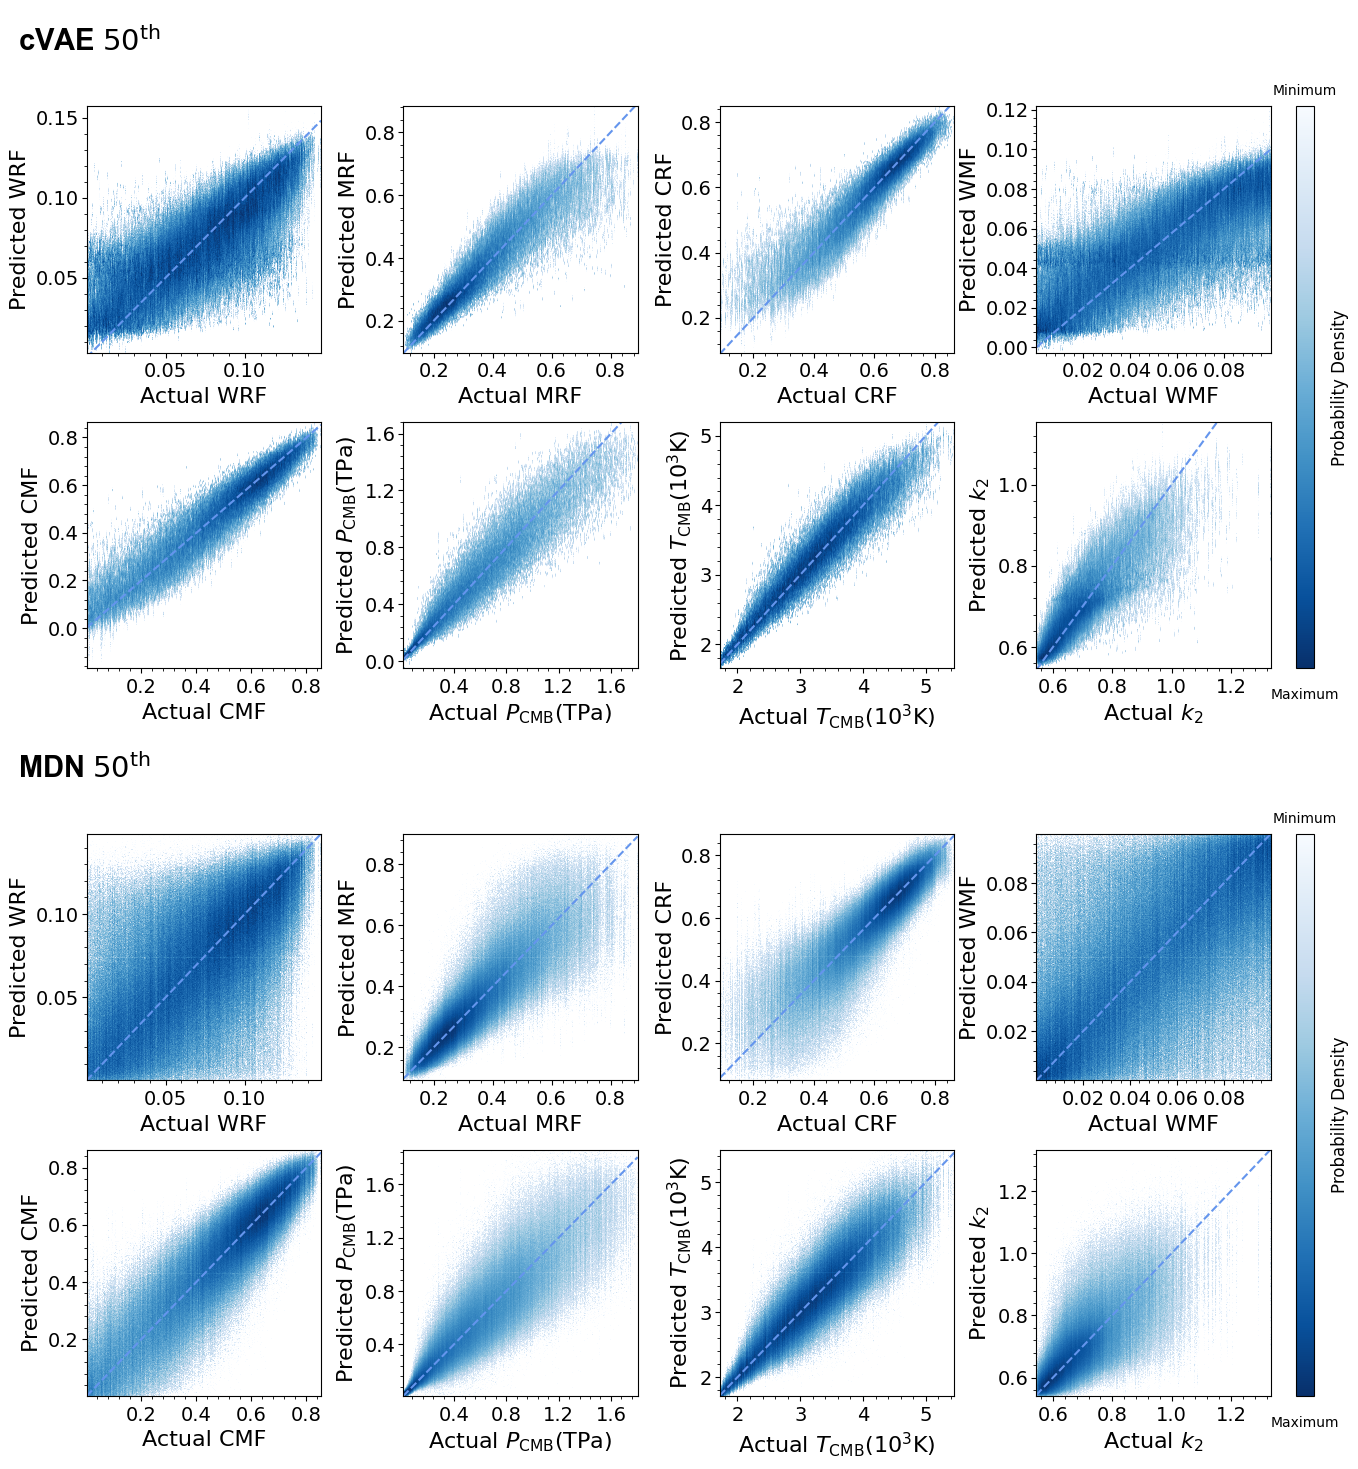

In [31]:
row, col = 3, 4
fig = plt.figure(figsize=(16, 18))
gs = gridspec.GridSpec(row * 2, col, figure=fig, height_ratios=[0.33, 3, 3, 0.33, 3, 3], hspace=0.4, wspace=0.35)

axs = []
for i in range(len(idxs)):
    tmp = []
    for o in range(len(output_parameters) + 4):
        idx = idxs[i][o]
        ax = fig.add_subplot(gs[idx[0], idx[1]])
        tmp.append(ax)

    axs.append(tmp)

count = 0
for ax in axs:
    sub_axs = ax[:4]
    for i, s_ax in enumerate(sub_axs):
        if i == 0:
            s_ax.text(-0.28, -0.5, ["cVAE $50^{\mathrm{th}}$", "MDN $50^{\mathrm{th}}$"][count], fontsize=21, fontweight='bold', fontname='Arial')
            s_ax.axis('off')

        else:
            s_ax.text(1, 1, '')
            s_ax.axis('off')

    count += 1

for axs_idx, n in enumerate(["cvae_50th", "mdn_50th"]):
    current_result = model_result_dicts[n]
    current_pred_inverse = current_result['model_pred_inverse'].reshape(75000, 20, 8)
    current_pred_min = current_pred_inverse.min(axis=1)
    current_pred_max = current_pred_inverse.max(axis=1)

    current_y_inverse = current_result['text_y_inverse']
    current_y_min = current_y_inverse.min(axis=0)
    current_y_max = current_y_inverse.max(axis=0)

    for o in range(len(output_parameters)):
        curr_axs = axs[axs_idx][4:][o]

        curr_axs.plot([current_y_min[o], current_y_max[o]], [current_y_min[o], current_y_max[o]], c='cornflowerblue', ls='--', zorder=2)

        param_t_repeat = np.repeat(current_y_inverse[:, o], 20)
        param_p = current_pred_inverse[:, :, o].reshape(-1)
        h = curr_axs.hist2d(
            param_t_repeat,
            param_p,
            bins=250,
            cmap='Blues',
            norm=LogNorm(),
            cmin=1,
            rasterized=True,
            label=n
        )
        chart_preference(curr_axs,
                         label_name='Actual ' + x_labels[o],
                         xlocator=xlocators[o],
                         xminorlocator=xminorlocators[o],
                         ylocator=xlocators[o],
                         yminorlocator=xminorlocators[o],
                         y_label='Predicted ' + x_labels[o],
                         display_zero_lines=False,
                         legend_display=False,
                         all_subplots_ylabel=True
                         )

        # curr_axs.set_box_aspect(1)

    cbar = fig.colorbar(
        h[3],
        ax=axs[axs_idx][4:],
        location='right',
        fraction=0.025,
        pad=0.02,
        aspect=30
    )

    cbar.ax.invert_yaxis()

    cbar.set_label(
        'Probability Density',
        rotation=90,
        labelpad=12,
        fontsize=12
    )

    cbar.ax.set_title('Minimum', fontsize=10, pad=8)

    cbar.ax.text(
        0.5, -0.035, 'Maximum',
        transform=cbar.ax.transAxes,
        ha='center',
        va='top',
        fontsize=10
    )

    cbar.set_ticks([])
    cbar.ax.minorticks_off()

# plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05, wspace=0.3, hspace=0.3)
plt.grid(False)
fig.savefig(os.path.join(img_save_path, 'heatmap_50th.pdf'), dpi=300, bbox_inches='tight', transparent=True)

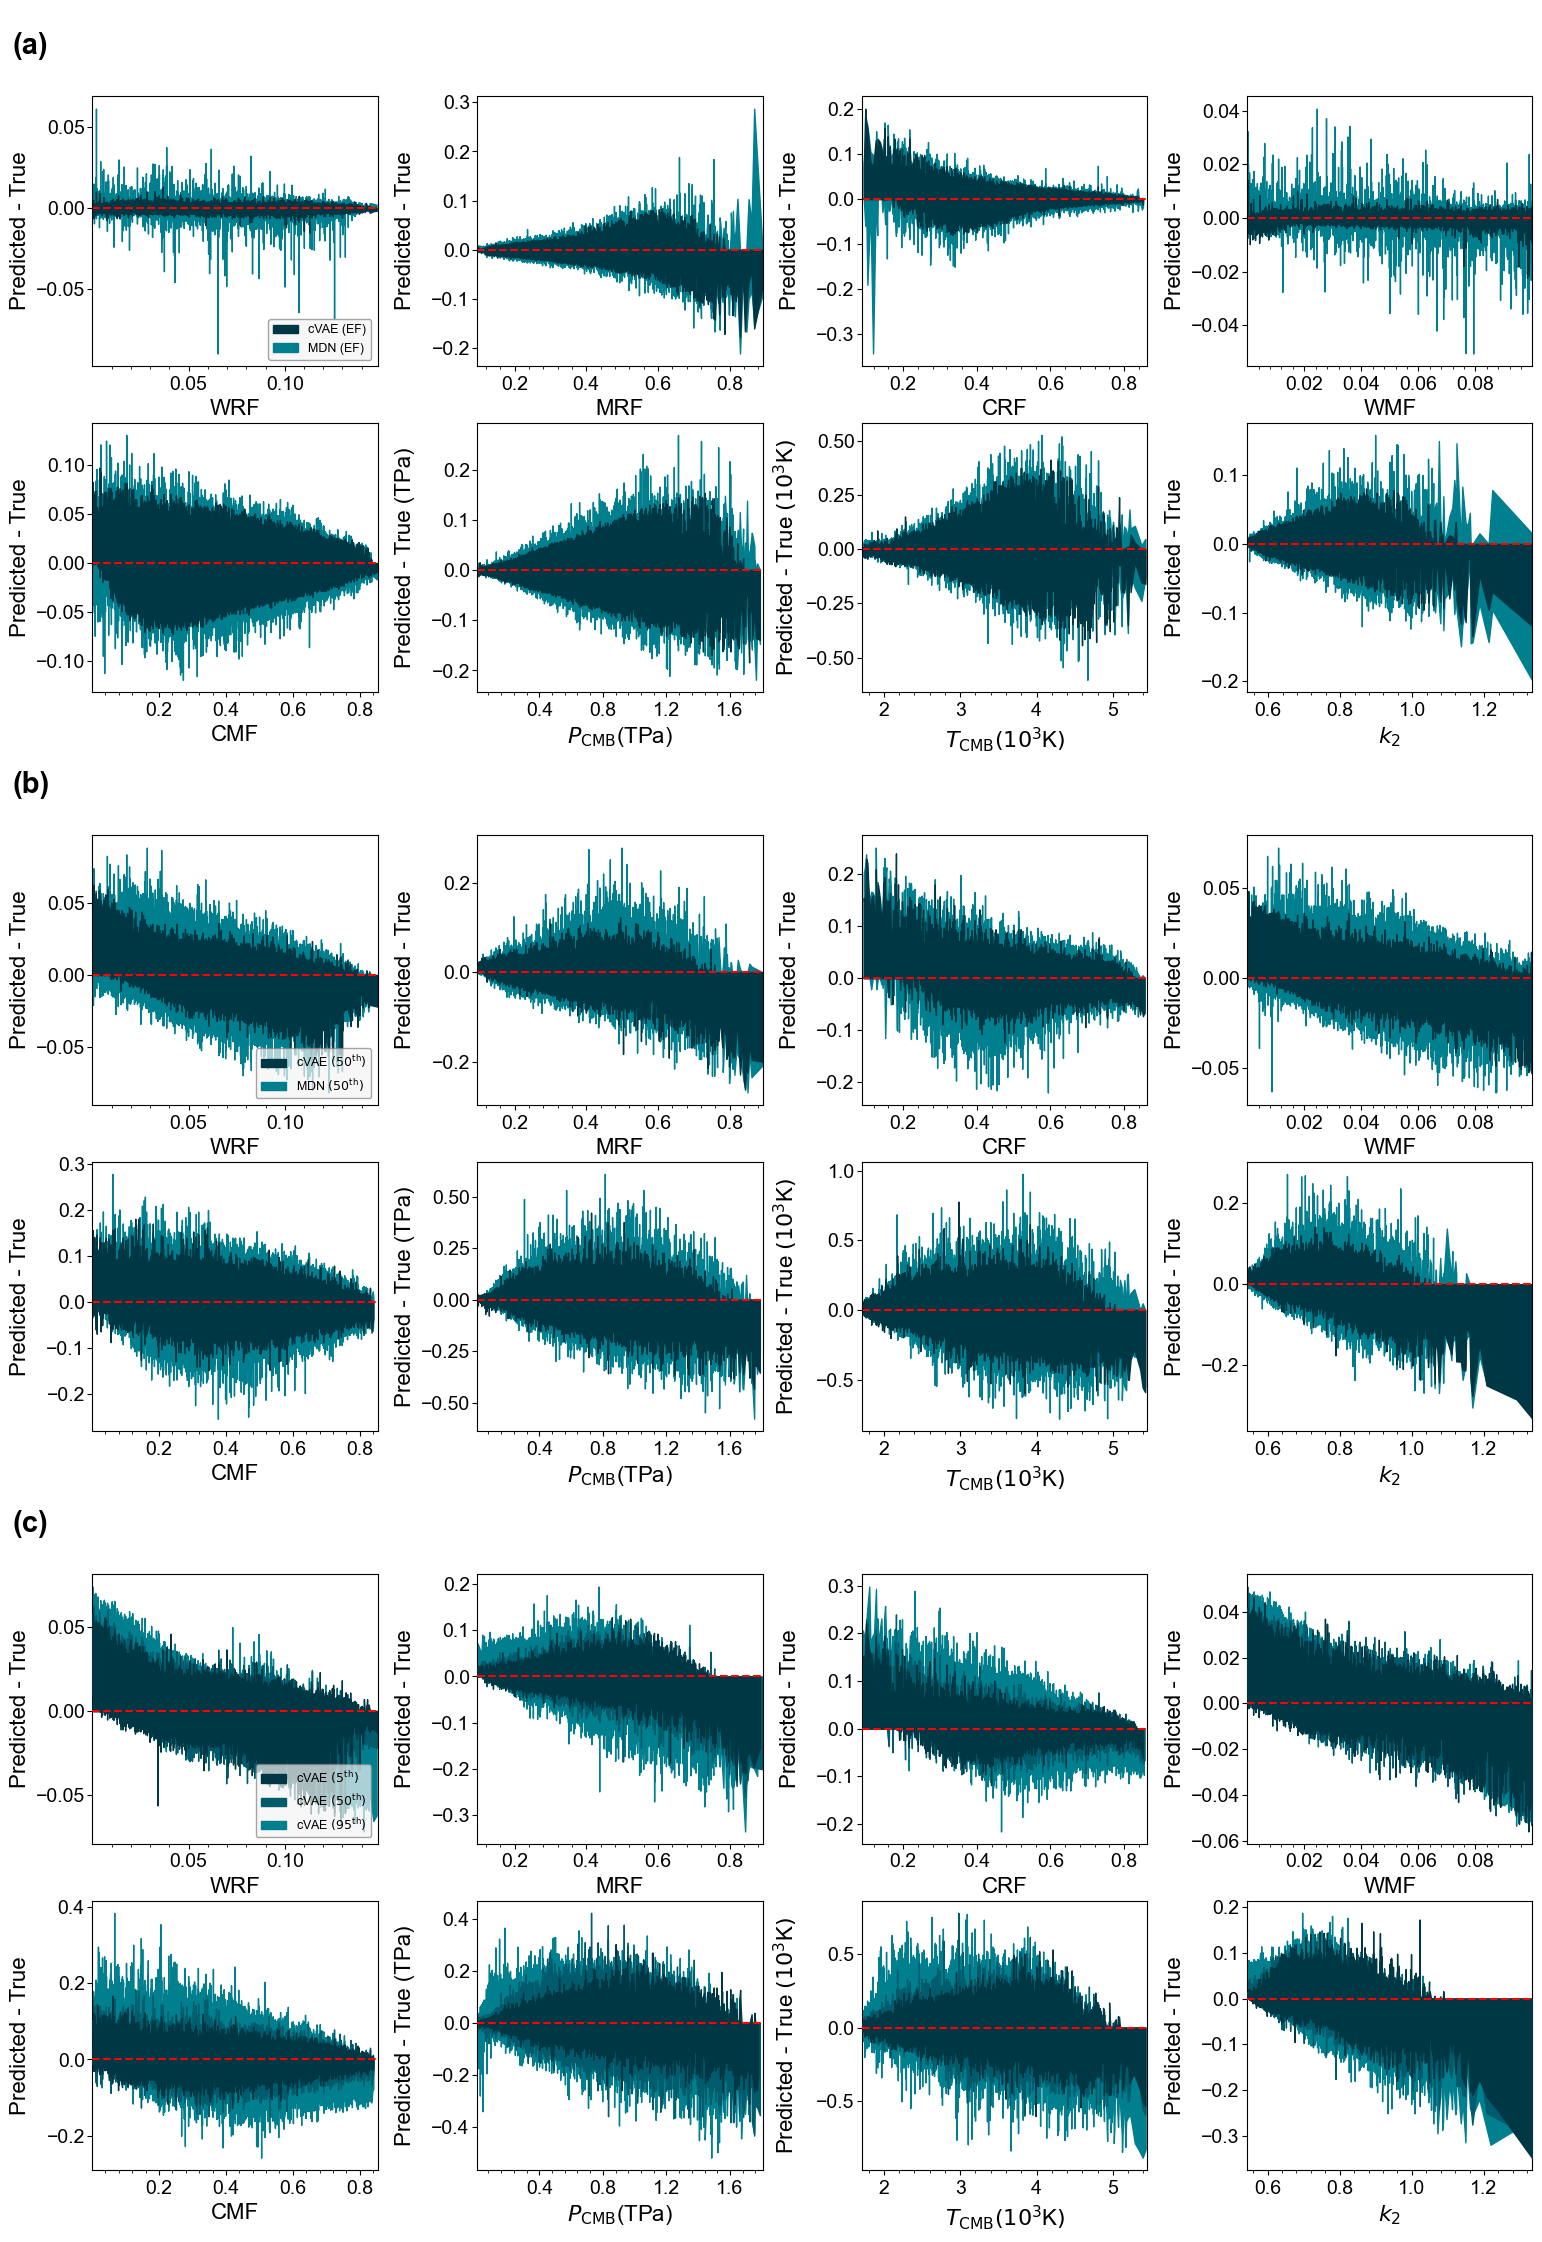

In [13]:
idxs = []
for l in [0, 3, 6]:
    idxs.append(idx_generator(l, l + 3, 4))

slide = 10
stride = slide
condition = 0
obs_error_trend_set = ["cvae_5th", "cvae_50th", "cvae_95th"]
ori_comparison_set = ["cvae_ori", "mdn_ori"]
obs_comparison_set = ["cvae_50th", "mdn_50th"]
set_name = ['ori_comparison', 'obs_comparison', 'obs_error']
serial = ['(a)', '(b)', '(c)']
alpha_set = [1.0, 0.8, 0.6, 0.4, 0.2]

row, col = 3, 4
fig = plt.figure(figsize=(16, 24))
gs = gridspec.GridSpec(row * 3, col, figure=fig, height_ratios=[0.33, 3, 3, 0.33, 3, 3, 0.33, 3, 3])

axs = []
for i in range(len(idxs)):
    tmp = []
    for o in range(len(output_parameters) + 4):
        idx = idxs[i][o]
        ax = fig.add_subplot(gs[idx[0], idx[1]])
        tmp.append(ax)

    axs.append(tmp)


count = 0
for ax in axs:
    sub_axs = ax[:4]
    for i, s_ax in enumerate(sub_axs):
        if i == 0:
            s_ax.text(-0.28, -0.5, serial[count], fontsize=21, fontweight='bold', fontname='Arial')
            s_ax.axis('off')

        else:
            s_ax.text(1, 1, '')
            s_ax.axis('off')

    count += 1


test_v = None
signed_error_scaler = None
for index, (n, s) in enumerate(zip(set_name, [ori_comparison_set, obs_comparison_set, obs_error_trend_set])):

    sub_dict = {k: model_result_dicts[k] for k in s}
    max_dis = [0] * len(output_parameters)
    min_dis = [0] * len(output_parameters)
    max_value = [0] * len(output_parameters)

    count = -1
    for k, v in sub_dict.items():
        count += 1
        for o in range(len(output_parameters)):

            sort_idx = np.argsort(v['text_y_inverse'][:, o])

            pred = v['model_pred_inverse'][:, o][sort_idx]
            true = v['text_y_inverse'][:, o][sort_idx]
            dis = (pred - true)    # sorted_pred - sorted_true


            if max(true) > max_value[o]:
                max_value[o] = max(true)

            windows = []
            slide_mean = []

            for i in range(0, len(true), stride):
                current_window = dis[i:i + slide]
                tmp = []
                positive_value = current_window[np.where(current_window > 0)]
                negative_value = current_window[np.where(current_window < 0)]

                if positive_value.size > 0:
                    positive_median = np.median(positive_value)
                    tmp.append(positive_median)

                if negative_value.size > 0:
                    negative_median = np.median(negative_value)
                    tmp.append(negative_median)

                if len(tmp) < 2:
                    tmp = [0 if tmp[0] < 0 else tmp[0], 0 if tmp[0] > 0 else tmp[0]]

                else:
                    if i != 0:
                        if tmp[0] > max_dis[o]:
                            max_dis[o] = tmp[0]

                        if tmp[1] < min_dis[o]:
                            min_dis[o] = tmp[1]

                windows.append(tmp)
                # slide_mean.append(true[i:i + slide].mean())
                slide_mean.append(np.median(true[i:i + slide]))

            windows = np.array(windows)
            xs = np.arange(0, len(true), stride)


            if condition == 2:
                if o == 0 and k == 'mdn_50th':
                    print(windows)
                    print("Max of this window: {}, Min of this Window: {}".format(max(windows[:, 0]), min(windows[:, 1])))
                    test_v = windows
                    test_d = dis

            tmp_label = k.split('_')

            if tmp_label[0].lower() == 'cvae':
                    tmp_label[0] = 'cVAE'

            elif tmp_label[0].lower() == 'mdn':
                    tmp_label[0] = 'MDN'

            if condition == 1:
                label_for_chart = tmp_label[0] + ' $({})$'.format(tmp_label[1].replace('th', '^{\mathrm{th}}'))

            elif condition == 0:

                label_for_chart = tmp_label[0] + ' (EF)'

            elif condition == 2:

                label_for_chart = tmp_label[0] + ' $({})$'.format(tmp_label[1].replace('th', '^{\mathrm{th}}'))

            ax = axs[index][4:][o]

            plot_amplitude(ax, len(sub_dict.keys()), colors_2, slide_mean, windows, count, label_for_chart)
            ax.set_xlim(min(true), max(true))

    current_ylocators = None
    current_yminilocator = None

    for o in range(len(output_parameters)):
        sign = ''
        if x_labels[o] == '$P_{\mathrm{CMB}}$(TPa)':
            sign = ' (TPa)'

        elif x_labels[o] == '$T_{\mathrm{CMB}}(10^{3}$K$)$':
            sign = ' $(10^{3}$K$)$'


        chart_preference(axs[index][4:][o],
                         len(sub_dict),
                         label_name=x_labels[o],
                         label_font_size=16,
                         tick_labelsize=14,
                         xlocator=xlocators[o],
                         xminorlocator=xminorlocators[o],
                         y_label='Predicted - True{}'.format(sign),
                         all_subplots_ylabel=True)

    condition += 1

fig.align_ylabels([ax for group in axs for ax in group])

plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05, wspace=0.35, hspace=0.3)
plt.grid(False)
fig.savefig(os.path.join(img_save_path, 'amplitude_{}.pdf'.format(slide)), dpi=300, bbox_inches='tight', transparent=True)
